# 2D POISSON EQUATIONS

It is basically a Laplace Equation with a source term. It is very important to solve incompressible NS for example where the continuity (I) and momemtum conservation equations (II) don't directly couple velocity and pressure.

We have to apply the divergent in momentum equation to create a pressure field that satisfied the kinematic condition imposed by the continuity.

Basic 2D Poisson equations:
$$\frac{\partial ^2 p}{\partial x^2} + \frac{\partial ^2 p}{\partial y^2} = b$$

Same discretization as in Laplace. Discrete solution now includes the $b^n_{i, j} * dx^2 *dy^2$ term

In [7]:
import numpy as np
from matplotlib import pyplot as plt, cm
from matplotlib import animation

Text(0, 0.5, '$y$')

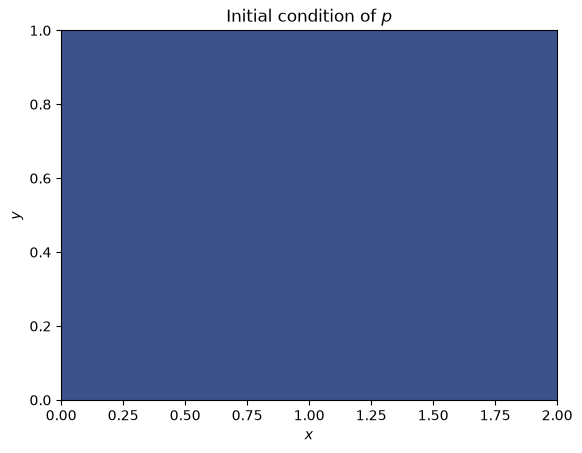

In [8]:
#space discretization
nx = 41
ny = 41
dx = 2 / (nx - 1)
dy = 2 / (ny - 1)

x = np.linspace(0, 2, nx)
y = np.linspace(0, 1, ny)

#solution parameters
crit = 1e-4

#'inital' condition
p = np.zeros((ny, nx)) #the first index is the row (y) and the second index is the column (x)

#boundary conditions
p[:, -1] = 0
p[:, 1] = 0
p[-1, :] = 0
p[1, :] = 0

#plot initial condition
fig, ax = plt.subplots()
ax.set_title('Initial condition of $p$')
contour = ax.contourf(x, y, p, levels= 20, cmap=cm.viridis)
ax.set_xlabel('$x$')
ax.set_ylabel('$y$')


Text(0, 0.5, '$y$')

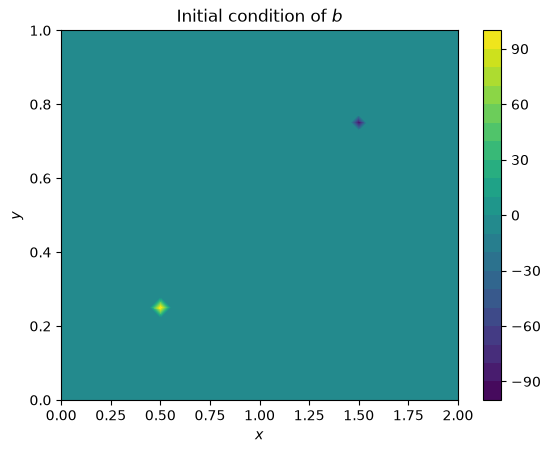

In [9]:
#poisson function b:
b = np.zeros((ny, nx))
b[int(0.5/dy), int(0.5/dx)] = 100
b[int(1.5/dy), int(1.5/dx)] = -100

#plot b
fig, ax = plt.subplots()
ax.set_title('Initial condition of $b$')
contour = ax.contourf(x, y, b, levels= 20, cmap=cm.viridis)
colorbar = fig.colorbar(contour)
ax.set_xlabel('$x$')
ax.set_ylabel('$y$')

In [10]:
err = 1
its = 0
p_solutions:list = []

while err > crit:
    p0 = p.copy()
    p_solutions.append(p0)
    
    #update interior points
    p[1:-1,1:-1] = ((dy**2 * (p0[2:,1:-1] + p0[:-2,1:-1]) +
                dx**2 * (p0[1:-1,2:] + p0[1:-1,:-2]) -
                dx**2 * dy**2 * b[1:-1,1:-1]) /
                (2 * (dx**2 + dy**2)))
    
    #apply boundary conditions
    p[0,:] = 0  # p = 0 @ x = 0
    p[-1:,] = 0 # p = 0 @ x = 2
    p[:,0] = 0 # p = 0 @ y = 0
    p[:,-1] = 0 # p = 0 @ y = 2  
    
    #compute error
    err = np.sum(np.abs(p - p0))
    its += 1

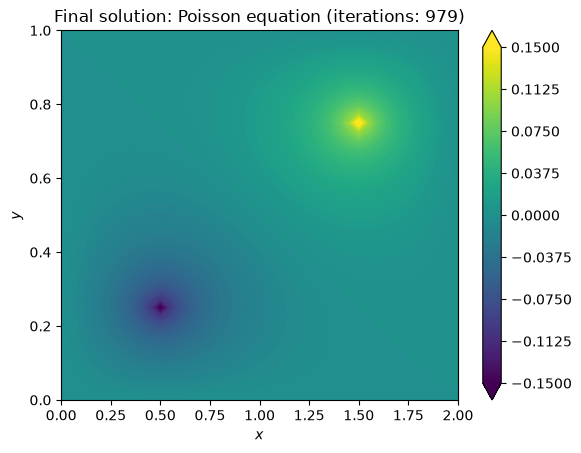

In [11]:
fig, ax = plt.subplots()
ax.set_title(f'Final solution: Poisson equation (iterations: {its})')
ax.set_xlabel('$x$')
ax.set_ylabel('$y$')
contour = ax.contourf(x, y, p_solutions[-1], levels= 100, cmap=cm.viridis)
vmin, vmax = -0.15, 0.15
levels = np.linspace(vmin, vmax, 101)

contour = ax.contourf(x, y, p_solutions[-1], levels=levels,
                      cmap=cm.viridis, extend='both')
colorbar = fig.colorbar(contour, ax=ax,
                        ticks=np.linspace(vmin, vmax, 9))

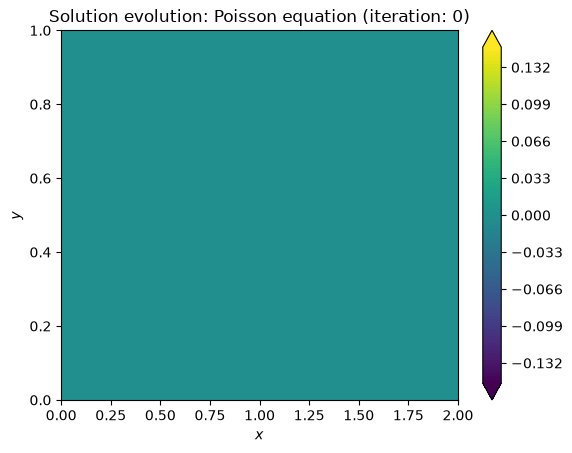

In [13]:
# Use uma figura nova para evitar eixos extras de execuções anteriores
fig, ax = plt.subplots()
frames = np.arange(0, len(p_solutions), 10)

contour = ax.contourf(
    x, y, p_solutions[0],
    levels=levels, cmap=cm.viridis, extend='both'
)
colorbar = fig.colorbar(contour, ax=ax, ticks=np.linspace(vmin, vmax, 9))
ax.set_xlabel('$x$')
ax.set_ylabel('$y$')

def update(frame):
    global contour

    contour.remove()
    contour = ax.contourf(
        x, y, p_solutions[frame],
        levels=levels, cmap=cm.viridis, extend='both'
    )
    colorbar.update_normal(contour)
    ax.set_title(f'Solution evolution: Poisson equation (iteration: {frame})')

anim = animation.FuncAnimation(
    fig, update, frames=frames, interval=10
)
anim.save('poisson_equation_solution_evolution.gif', writer='pillow', fps=30)